# Higgs-portal paired sample validation

Read-only checks of hits, cells and particles for the corrected Higgs-portal pilot. Pu0 is **blue**, pu200 **green**. The two samples have the same physics point but **different hard-scatter events**: the current pu0 entry came from original event 7 and pu200 from signal event 0. Shared local event IDs do not imply pairing.

Distribution overlays are normalized and use shared bins. One event per setting is a smoke test, not a precision physics or resolution measurement. No ACTS, Docker, PyTorch or published-data download is needed.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "notebooks/validation/higgs_portal_validation.py").is_file())
sys.path.insert(0, str(REPO))
from notebooks.validation import higgs_portal_validation as validation
from notebooks.validation import paired_vs_published as paired

PILOT_ROOT = REPO.parent / "exports/higgs-portal-pilot-run1-n1"
PAIRED_ROOT = PILOT_ROOT / "paired"  # Current recovery-only files
BASELINE_PAIRED_ROOT = PILOT_ROOT / "paired.before-recovery-v2"
PERIGEE_VALIDATION_ROOT = PILOT_ROOT / "validation/perigee_reference"
EVENT = 0
PARTICLE_COHORT = "generator_charged_with_hits"  # Or "all", "charged_with_hits", "displaced_charged_with_hits".
SCATTER_LIMIT = 15000
SEED = 7
GALLERY_SAMPLE = "pu200"
CLUSTER_TARGET_SIZES = (1, 2, 4, 8, 16, 32)
CHECK_SOURCE_HASHES = True

pd.set_option("display.max_columns", 30)
print("Pilot:", PILOT_ROOT)
print("Current paired files:", PAIRED_ROOT)
print("Original comparison files:", BASELINE_PAIRED_ROOT)
print("Selected local event:", EVENT, "in each independent sample")
before_hashes = validation.file_hashes(PAIRED_ROOT) if CHECK_SOURCE_HASHES else None

Pilot: /misc/home/atlas/dittmeier/git/cluster_extraction/exports/higgs-portal-pilot-run1-n1
Current paired files: /misc/home/atlas/dittmeier/git/cluster_extraction/exports/higgs-portal-pilot-run1-n1/paired
Original comparison files: /misc/home/atlas/dittmeier/git/cluster_extraction/exports/higgs-portal-pilot-run1-n1/paired.before-recovery-v2
Selected local event: 0 in each independent sample


## Production evidence and event selection

Check completion markers and inspect the simulation gate and recovery provenance. The published pu0 ROOT input was already simulated; only pu200 was newly simulated in this pilot. LLP endpoint checks below concern that new pu200 simulation.

Particle `vx/vy/vz` are **production vertices**, not decay endpoints. An LLP's own production vertex should be near its collision vertex. Displaced daughter production vertices, perigee parameters, and the saved simulation endpoint check provide complementary evidence. `vertex_primary` is an event-local vertex identifier, not a boolean or guaranteed signal tag.

In [2]:
pilot = json.loads((PILOT_ROOT / "pilot.json").read_text())
complete = json.loads((PAIRED_ROOT / "complete.json").read_text())
simulation_check = json.loads((PILOT_ROOT / "simulation_validation.json").read_text())
assert pilot.get("complete") and pilot.get("simulation_validated"), "Pilot is not complete and validated"
assert set(complete["samples"]) == {"pu0", "pu200"}
display(pd.Series(pilot["physics"], name="Physics point").to_frame())
display(pd.json_normalize(simulation_check))
display(pd.DataFrame(pilot["selected_signal_events"]))
print("Event pairing:", pilot["comparison_note"])
if "writer_recovery" in pilot:
    recovery = pilot["writer_recovery"]
    display(pd.DataFrame([{
        key: recovery[key] for key in ("original_entries", "recovered_events", "kept_entries",
                                      "duplicate_branch_comparisons", "original_sha256", "recovered_sha256")
    }]))
print("Original simulation timing:", (PILOT_ROOT / "simulation/pu200/timing_summary.txt").read_text())

,Physics point
higgs_mass_GeV,125.0
llp_mass_GeV,55.0
llp_ctau_mm,100.0
llp_pdg,36
decay,h -> aa -> b bbar b bbar


,events,root_to_hepmc,llps_checked,maximum_llp_endpoint_error_mm,charged_descendants_checked,displaced_charged_descendants_checked,decay_momentum_adjusted_matches,maximum_decay_momentum_relative_adjustment,decay_momentum_matching_relative_tolerance,displacement_gate_exercised,interpretation
0,1,"[{'root_entry': 0, 'hepmc_event': 0}]",2,1.914843e-13,26,22,20,0.000128,0.001,True,"Pilot sanity gate, not a complete LLP physics ..."


,source_entry,source_event_number,logical_event
0,0,0,0


Event pairing: pu0 ROOT entries and pu200 signal selections are not assumed event-by-event paired


,original_entries,recovered_events,kept_entries,duplicate_branch_comparisons,original_sha256,recovered_sha256
0,2,1,[0],189,80b0df62bd56f4f97a0d4e16e87af9ecc6f45ab9ab74fa...,60a6fe572c9ebf3f95dbc8c9b0fc99a304ba3edaa564b1...


Original simulation timing: 

Timing Report (20261024_214515)
DD4hep Simulation              : 859.95 seconds
--------------------------------------------------
Total time                     : 859.95 seconds


## Counts, schemas and associations

Loads only the selected event. Particle files are event-row/list-column tables, whereas hits and cells have one row per measurement or cell. Checks use the full measurement key:
`(campaign, dataset, version, run, local_event, measurement_id)`.

Every cell must have exactly one parent hit with the same geometry; every hit must have cells. Particle references and scalar labels are checked against this event's particles. Null scalar labels are permitted for multi-particle hits; contributor lists remain authoritative. Legacy converted-label disagreements and incomplete truth are reported separately, not hidden.

In [3]:
samples = validation.load_samples(PAIRED_ROOT, EVENT)
analyses = {name: sample.analysis for name, sample in samples.items()}
checks = validation.integrity(samples)
display(checks)
display(validation.coverage(samples))
display(pd.DataFrame([
    dict(sample=name, measurements=sample.hits.num_rows, cells=sample.cells.num_rows,
         particles=len(sample.particles), particle_memory_MiB=sample.particles.memory_usage(deep=True).sum()/2**20,
         cell_analysis_memory_MiB=sample.analysis.cells.memory_usage(deep=True).sum()/2**20)
    for name, sample in samples.items()
]))
legacy_disagreements = pd.DataFrame([
    dict(sample=name, **row)
    for name, sample in samples.items()
    for row in sample.report.get("converted_label_disagreement_examples", [])
])
display(legacy_disagreements)

,event,measurements,cells,particles,simhit_links,null_particle_labels,multi_particle_measurements,unresolved_simhit_links,incomplete_truth_measurements,converted_label_disagreements,orphan_cells,hits_without_cells,missing_parent_ids,association_checks
sample,,,,,,,,,,,,,,
pu0,0,2910,15126,2908,3026,71,71,0,0,0,0,0,0,PASS
pu200,0,180306,853809,221842,187259,5044,5044,0,0,1,0,0,0,PASS


,sample,table,feature,dtype,role
0,pu0,hits,campaign,string,identifier / integrity
1,pu0,hits,dataset,string,identifier / integrity
2,pu0,hits,version,string,identifier / integrity
3,pu0,hits,run,uint32,identifier / integrity
4,pu0,hits,local_event,uint32,identifier / integrity
...,...,...,...,...,...
93,pu200,particles,primary,list<element: bool>,distribution / missingness
94,pu200,particles,vertex_primary,list<element: uint16>,distribution / missingness
95,pu200,particles,parent_id,list<element: int64>,identifier / integrity
96,pu200,particles,perigee_d0,list<element: float>,distribution / missingness


,sample,measurements,cells,particles,particle_memory_MiB,cell_analysis_memory_MiB
0,pu0,2910,15126,2908,0.490993,6.006024
1,pu200,180306,853809,221842,37.447130,338.210223


,sample,local_event,measurement_id,converted_particle_id,particle_ids
0,pu200,0,82750,172987,[172986]


## Missing and non-finite values

The table counts both nulls and NaN/infinity. Some perigee values are undefined, particularly for neutral particles or particles without a useful tracker trajectory. Null strip `pixel_code` values are intentional. These populations must not be silently filled or treated as pixel-encoding failures.

,sample,table,feature,entries,nonfinite,fraction
17,pu0,particles,perigee_d0,2908,1307,0.449450
18,pu0,particles,perigee_z0,2908,1307,0.449450
22,pu0,particles,eta,2908,7,0.002407
32,pu0,hits,particle_id,2910,71,0.024399
33,pu0,hits,converted_particle_id,2910,85,0.029210
36,pu0,cells,pixel_code,15126,8536,0.564326
54,pu200,particles,perigee_d0,221842,85213,0.384116
55,pu200,particles,perigee_z0,221842,85213,0.384116
59,pu200,particles,eta,221842,1342,0.006049
69,pu200,hits,particle_id,180306,5044,0.027975


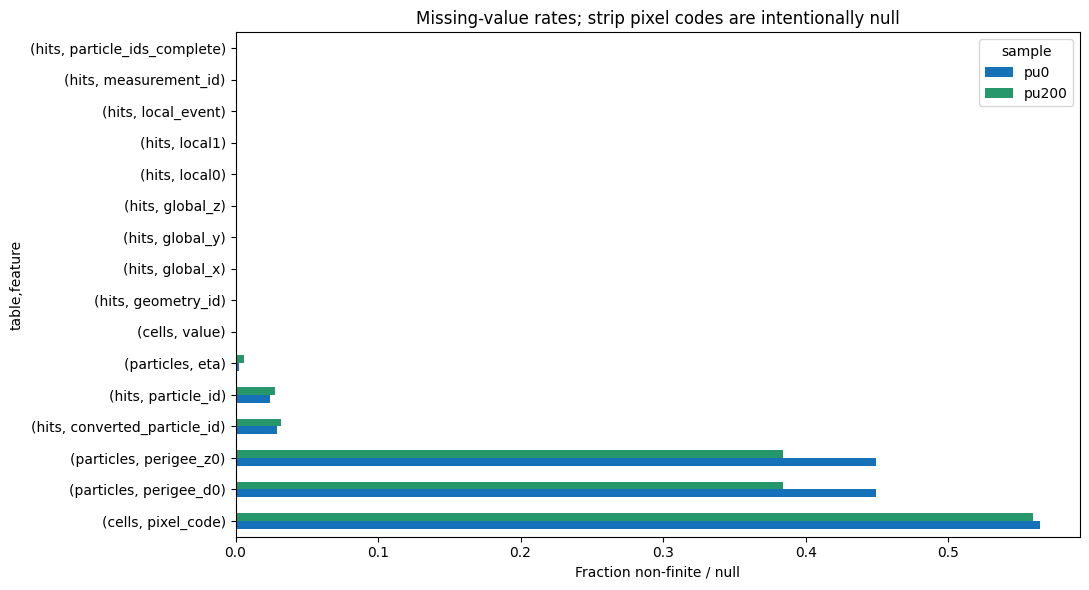

,sample,cohort,particles,finite_d0,finite_z0
0,pu0,all,2908,1601,1601
1,pu0,generator_charged_with_hits,125,124,124
2,pu0,charged_with_hits,619,284,284
3,pu0,displaced_charged_with_hits,530,195,195
4,pu200,all,221842,136629,136629
5,pu200,generator_charged_with_hits,7257,7256,7256
6,pu200,charged_with_hits,39659,16610,16610
7,pu200,displaced_charged_with_hits,32814,9765,9765


In [4]:
nonfinite = validation.nonfinite_rates(samples)
display(nonfinite[nonfinite.nonfinite > 0])
rates = nonfinite.pivot(index=["table", "feature"], columns="sample", values="fraction").fillna(0)
rates = rates.loc[rates.max(axis=1).nlargest(16).index]
if rates.to_numpy().max() > 0:
    rates.plot.barh(figsize=(11, 6), color=[paired.PILEUP_COLORS[name] for name in rates.columns])
    plt.xlabel("Fraction non-finite / null")
    plt.title("Missing-value rates; strip pixel codes are intentionally null")
    plt.tight_layout()
    plt.show()
display(pd.DataFrame([
    dict(sample=name, cohort=cohort, particles=len(frame),
         finite_d0=int(np.isfinite(frame.perigee_d0).sum()),
         finite_z0=int(np.isfinite(frame.perigee_z0).sum()))
    for name, sample in samples.items()
    for cohort in ("all", "generator_charged_with_hits", "charged_with_hits", "displaced_charged_with_hits")
    for frame in [validation.particle_selection(sample.particles, cohort)]
]))

## Particle kinematics and displaced vertices

The default cohort is generator-origin charged particles (`primary == True`) with at least one **SimTrackerHit**. This excludes Geant4-created material secondaries, but is **not** a signal-only selection: pileup generator particles also qualify. The SimTrackerHit count need not equal the number of reconstructed measurements linked to a particle. Set `PARTICLE_COHORT` above to inspect all particles or the displaced subset (`production_r > 10 mm`), which also includes material secondaries.

Plots use full-event statistics, common bins and logarithmic density axes to expose tails. Categorical plots show the most common categories and retain full-event denominators. Momentum/energy are in GeV, positions/perigee in mm, time in ns.

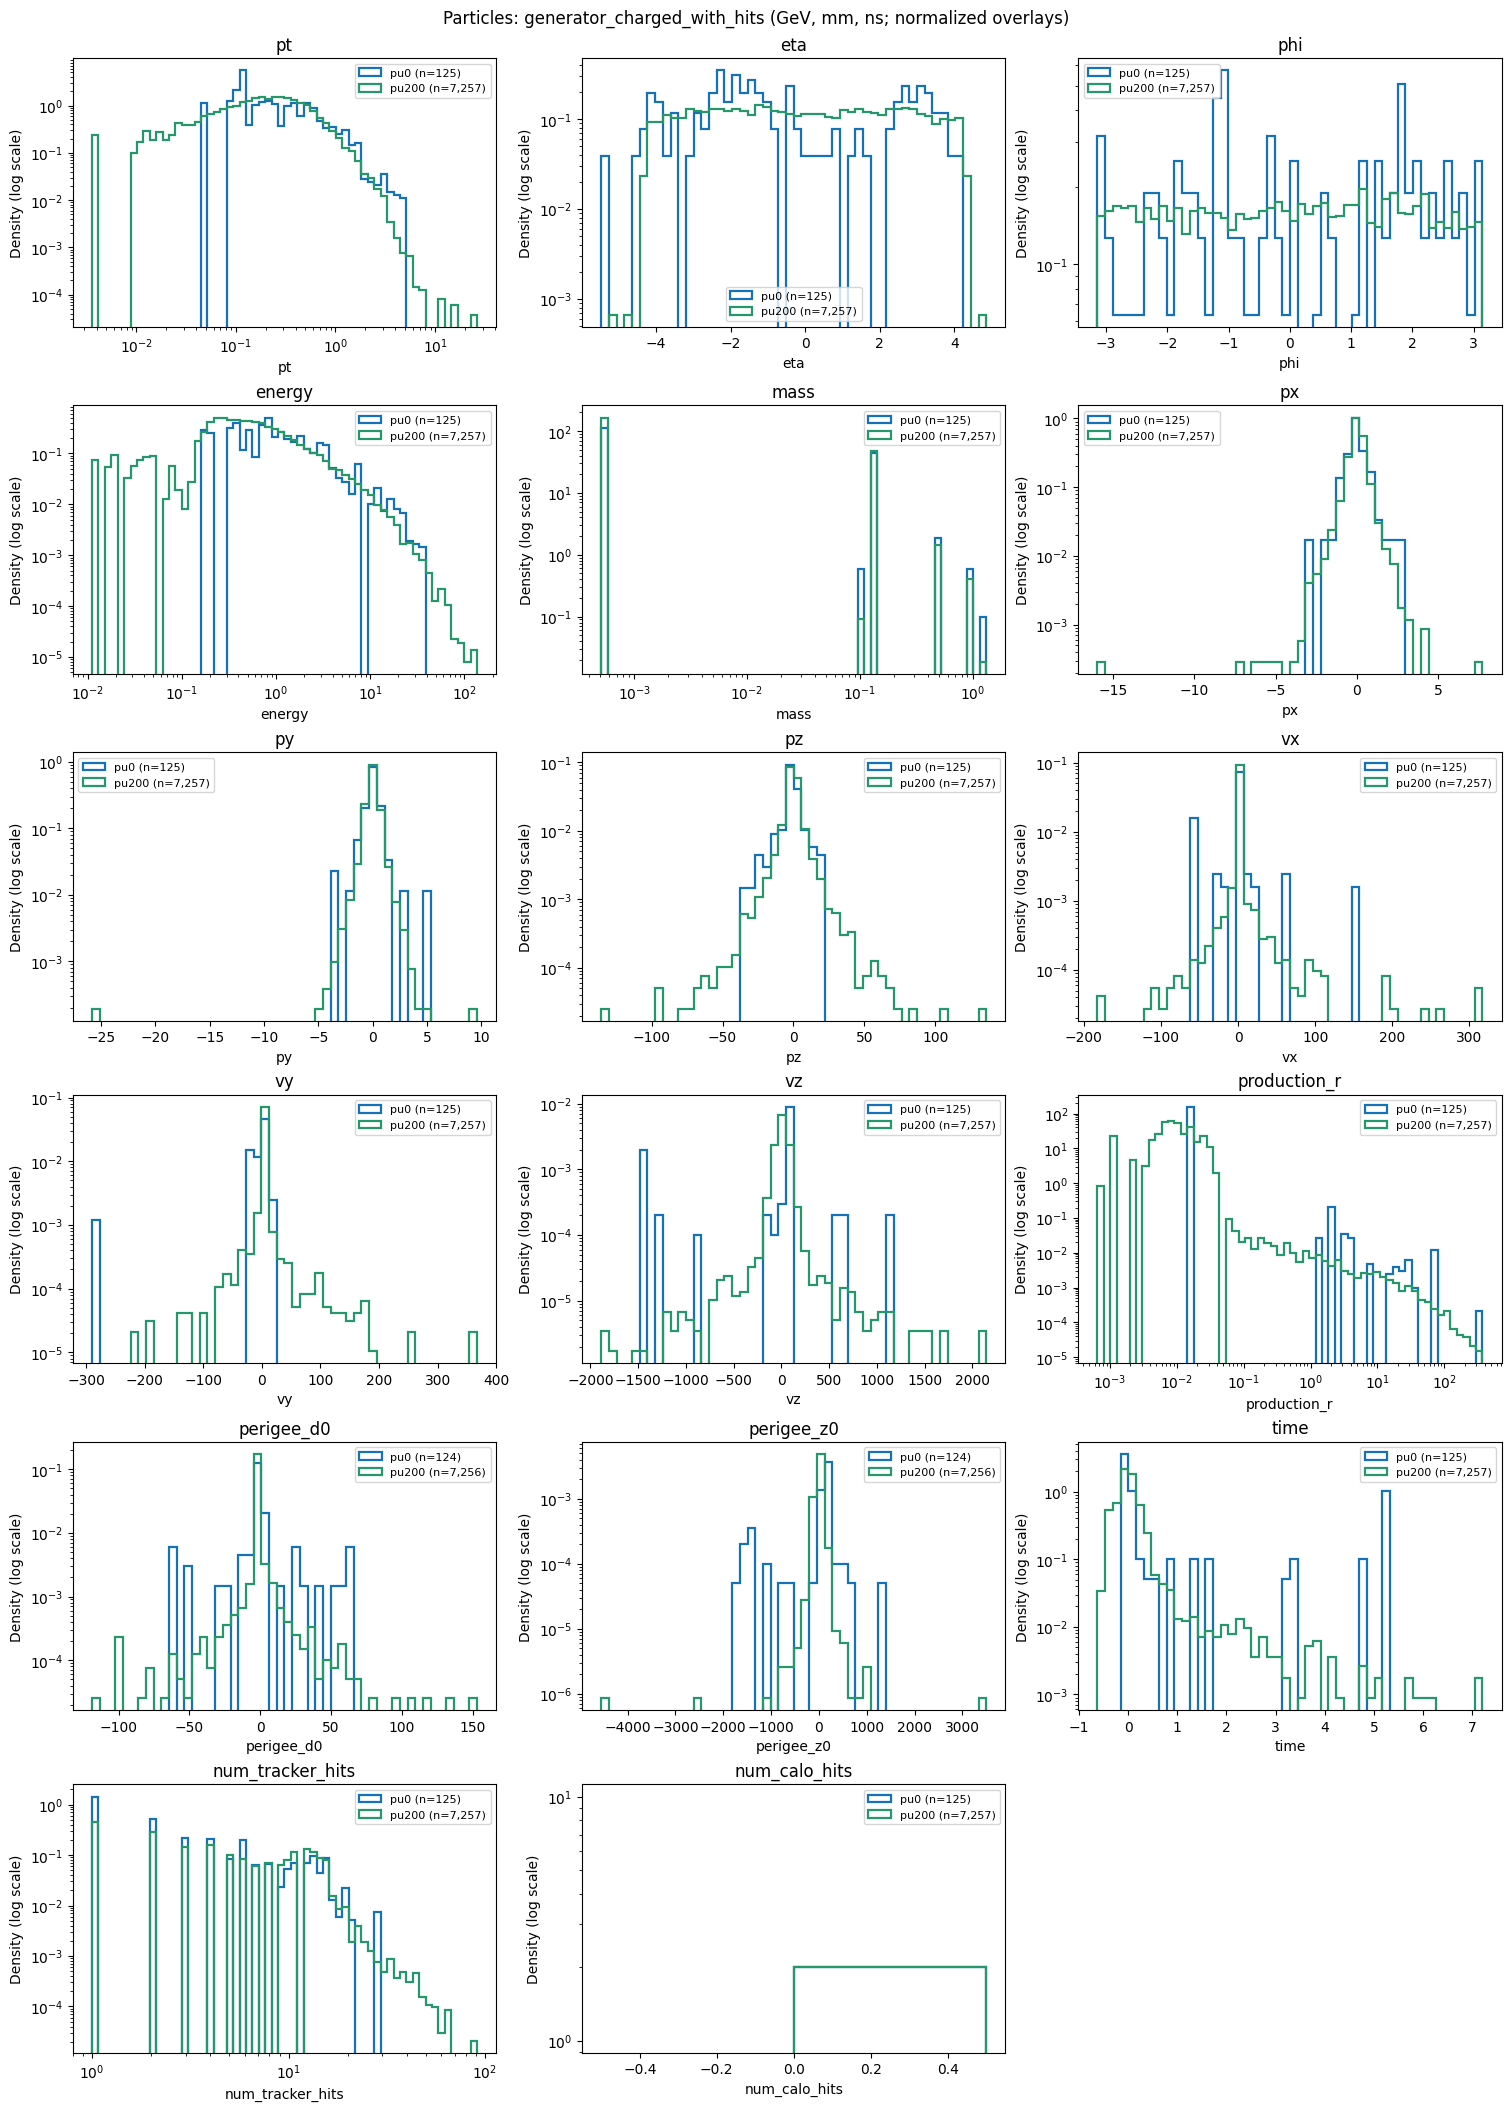

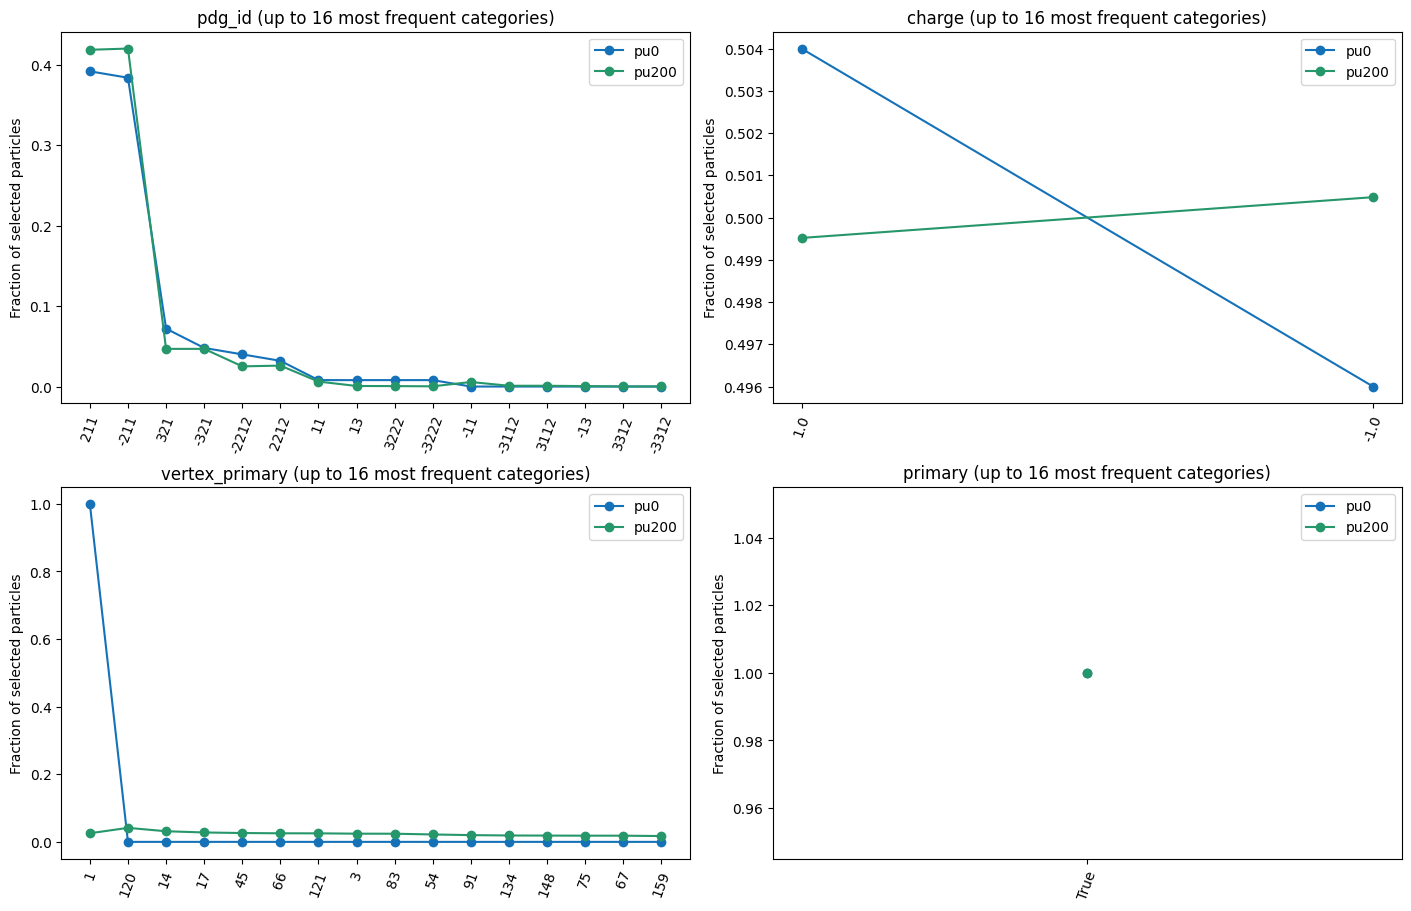

,particle_id,pdg_id,mass,pt,px,py,pz,vx,vy,vz,production_r,sample
0,614,36,55.0,13.383664,11.055432,-7.543200,-190.254196,-0.003953,0.014816,121.691368,0.015335,pu0
1,615,36,55.0,19.361447,-17.650900,-7.956844,-479.348297,-0.003953,0.014816,121.691368,0.015335,pu0
2,1446,36,55.0,9.787779,2.492378,9.465129,-11.559495,-0.000026,-0.017426,106.342682,0.017426,pu200
3,1447,36,55.0,35.275226,5.901621,34.778046,-84.921577,-0.000026,-0.017426,106.342682,0.017426,pu200


,sample,llps,charged_with_hits,displaced_charged_with_hits
0,pu0,2,619,530
1,pu200,2,39659,32814


In [5]:
validation.plot_particles(samples, PARTICLE_COHORT)
llps = pd.concat([
    sample.particles.loc[sample.particles.pdg_id.abs() == 36,
        ["particle_id", "pdg_id", "mass", "pt", "px", "py", "pz", "vx", "vy", "vz", "production_r"]].assign(sample=name)
    for name, sample in samples.items()
], ignore_index=True)
display(llps)
display(pd.DataFrame([
    dict(sample=name, llps=int((sample.particles.pdg_id.abs() == 36).sum()),
         charged_with_hits=len(validation.particle_selection(sample.particles)),
         displaced_charged_with_hits=len(validation.particle_selection(sample.particles, "displaced_charged_with_hits")))
    for name, sample in samples.items()
]))

## Detector coverage and hit features

Production vertices and measurement positions use separate panels. Dense spatial views use deterministic sampling only; integrity counts and histograms use the complete selected events. Both pileup settings appear on the same axes. Hit `local0/local1` are signed sensor-local coordinates, not channel addresses.

No hit positions have been recomputed using quantized cell codes.

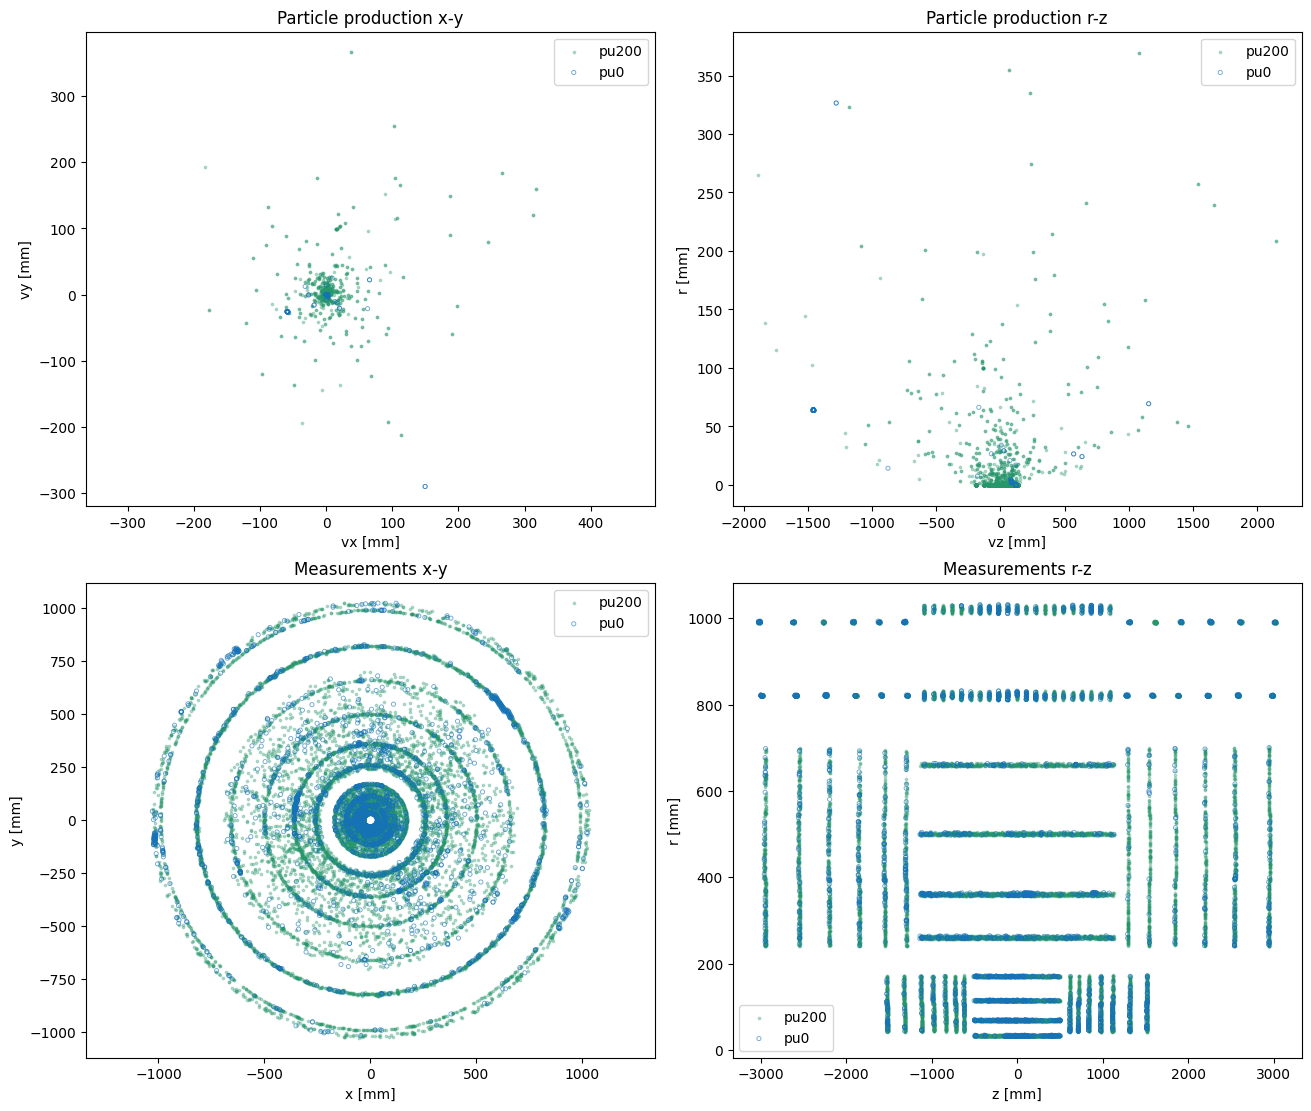

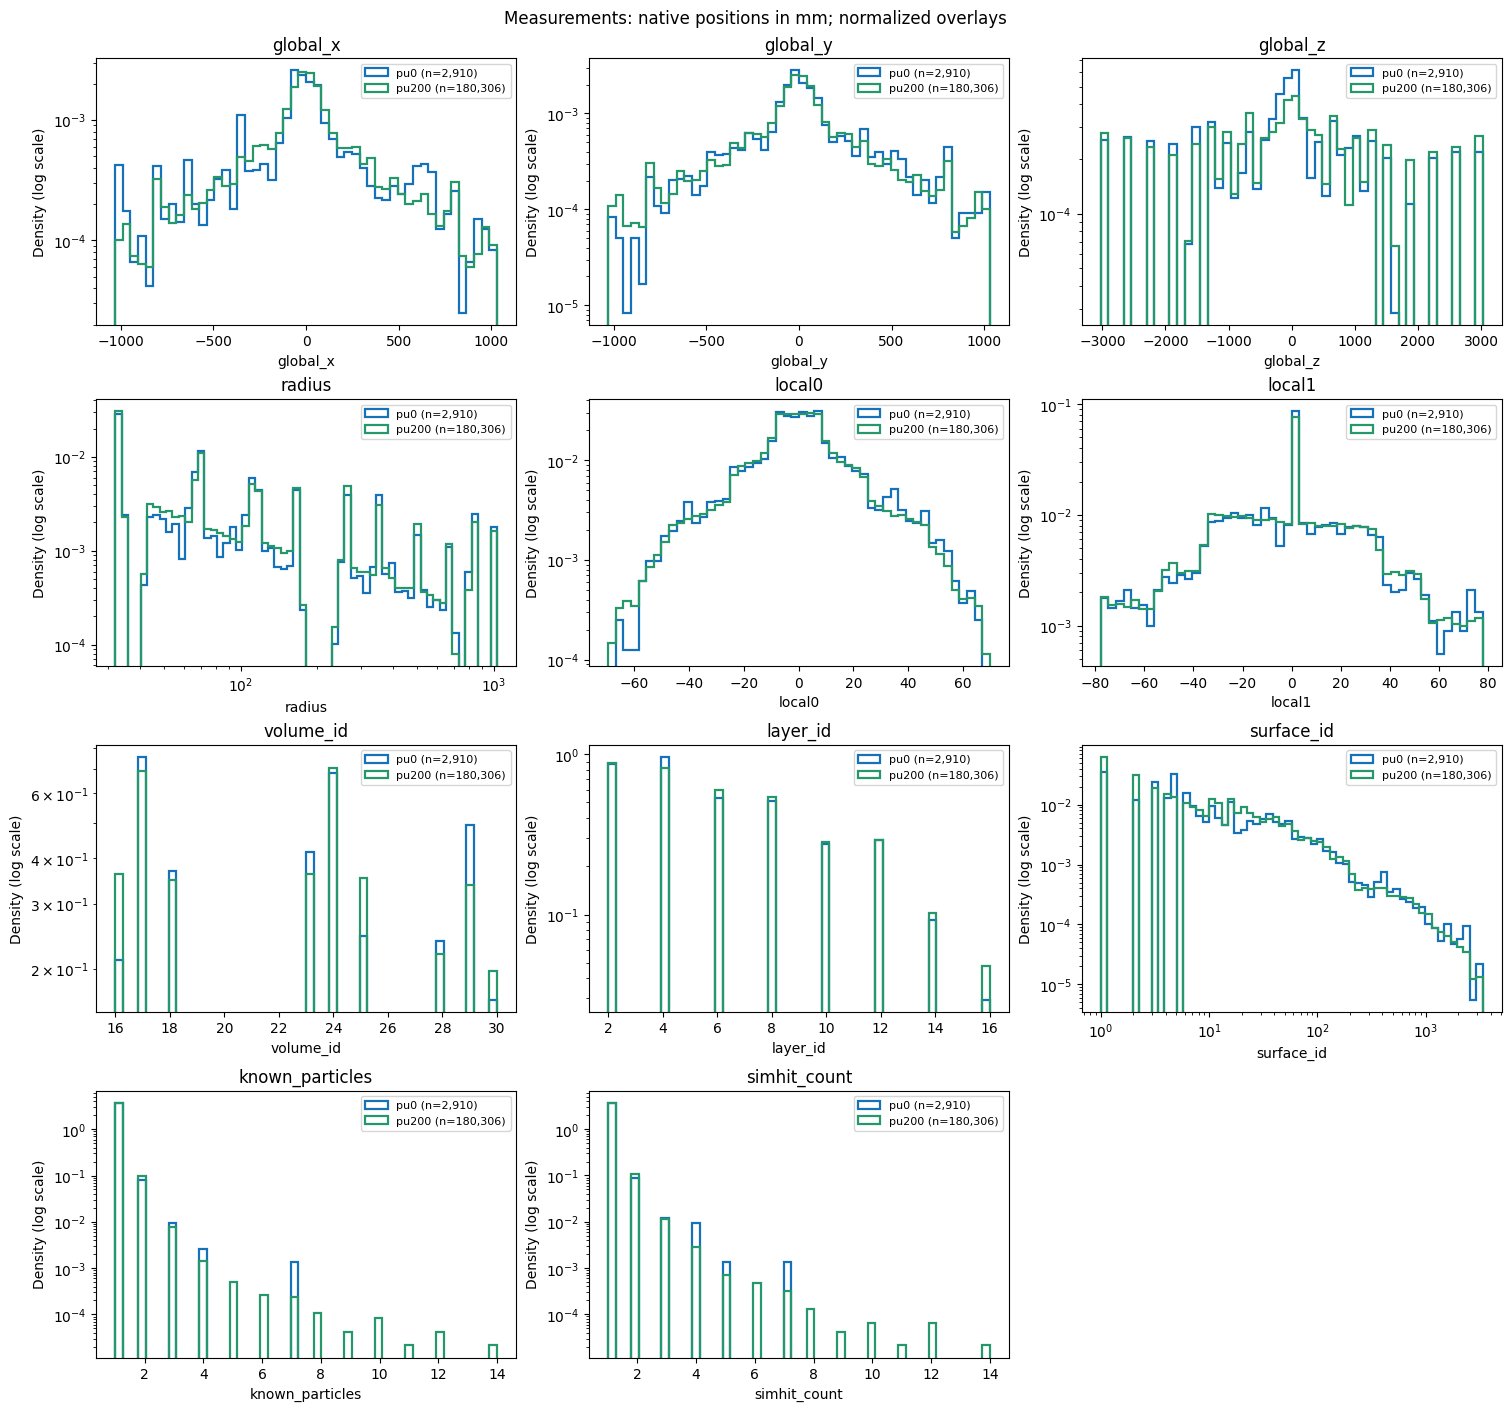

In [6]:
validation.plot_spatial(samples, SCATTER_LIMIT, SEED, PARTICLE_COHORT)
validation.plot_hits(samples)

## Cells, cluster sizes and contributors

Activation remains the native ACTS path-length proxy in mm, after its configured noise/threshold/merging. A large activation does not by itself imply several particles. Particle multiplicity below belongs to the **parent cluster**, not to an individual cell. Incomplete truth is a separate category.

Cell and cluster denominators are reported separately. Full-range survival curves and largest-cell tables retain rare extremes.

,sample,local_event,detector_type,clusters,cells,incomplete_clusters,maximum_activation,max_cell_parent_particles,max_cell_parent_simhits,max_cell_truth_complete,cell_tail_fraction,cluster_tail_fraction,complete_truth_tail_cells,multi_particle_parent_fraction_of_complete_tail
0,pu0,0,Long strips,728,4016,0,7.088085,1,1,True,0.010956,0.027473,44,0.454545
1,pu0,0,Pixels,1088,6590,0,0.688644,7,7,True,0.000152,0.000919,1,1.000000
2,pu0,0,Short strips,1094,4520,0,0.634113,2,2,True,0.003319,0.010969,15,0.333333
3,pu200,0,Long strips,38036,187748,0,9.452148,2,3,True,0.024900,0.044984,4675,0.386952
4,pu200,0,Pixels,70763,375843,0,1.205180,12,12,True,0.000029,0.000127,11,1.000000
5,pu200,0,Short strips,71507,290218,0,2.200541,6,6,True,0.005668,0.013202,1645,0.275380


,sample,local_event,detector_type,truth_complete,known_particles,cells,activation_median,activation_q95,activation_q995,activation_max,tail_cells,cell_tail_fraction,clusters,tail_clusters,cluster_tail_fraction,diagnostic_threshold
0,pu0,0,Long strips,True,1,2854,0.151583,0.297031,0.635146,7.088085,24,0.008409,705,14,0.019858,0.5
1,pu0,0,Long strips,True,2,1132,0.110075,0.297670,0.561125,4.195377,18,0.015901,22,5,0.227273,0.5
2,pu0,0,Long strips,True,3,30,0.238011,0.474791,0.994777,1.068213,2,0.066667,1,1,1.000000,0.5
3,pu0,0,Pixels,True,1,5541,0.049445,0.117252,0.139092,0.180287,0,0.000000,1072,0,0.000000,0.5
4,pu0,0,Pixels,True,2,569,0.047770,0.072635,0.148866,0.186218,0,0.000000,10,0,0.000000,0.5
5,pu0,0,Pixels,True,3,194,0.044086,0.089761,0.130093,0.160661,0,0.000000,3,0,0.000000,0.5
6,pu0,0,Pixels,True,4,42,0.048422,0.188153,0.397138,0.450228,0,0.000000,2,0,0.000000,0.5
7,pu0,0,Pixels,True,7,244,0.047158,0.076486,0.370901,0.688644,1,0.004098,1,1,1.000000,0.5
8,pu0,0,Short strips,True,1,3900,0.102169,0.238050,0.457436,0.540561,10,0.002564,1062,7,0.006591,0.5
9,pu0,0,Short strips,True,2,554,0.099788,0.250826,0.507970,0.634113,4,0.007220,29,4,0.137931,0.5


,sample,campaign,dataset,version,run,local_event,measurement_id,detector_type,volume_id,channel0,channel1,value,n_cells,activation_sum,known_particles,simhit_count,truth_complete
0,pu0,hard_scatter,higgs_portal,v2_cells_pilot,1,0,2604,Long strips,29,79,0,7.088085,2,7.528901,1,1,True
1,pu0,hard_scatter,higgs_portal,v2_cells_pilot,1,0,2689,Long strips,29,252,0,4.195377,4,8.136470,2,2,True
2,pu0,hard_scatter,higgs_portal,v2_cells_pilot,1,0,2689,Long strips,29,253,0,3.592250,4,8.136470,2,2,True
3,pu0,hard_scatter,higgs_portal,v2_cells_pilot,1,0,2711,Long strips,29,504,0,3.260959,10,5.519304,2,4,True
4,pu0,hard_scatter,higgs_portal,v2_cells_pilot,1,0,2800,Long strips,30,518,0,1.947662,1,1.947662,1,1,True
5,pu0,hard_scatter,higgs_portal,v2_cells_pilot,1,0,2366,Long strips,28,76,0,1.890563,2,3.242562,1,1,True
6,pu0,hard_scatter,higgs_portal,v2_cells_pilot,1,0,2366,Long strips,28,77,0,1.351998,2,3.242562,1,1,True
7,pu0,hard_scatter,higgs_portal,v2_cells_pilot,1,0,2606,Long strips,29,476,0,1.068213,30,7.739457,3,3,True
8,pu0,hard_scatter,higgs_portal,v2_cells_pilot,1,0,2711,Long strips,29,500,0,1.060021,10,5.519304,2,4,True
9,pu0,hard_scatter,higgs_portal,v2_cells_pilot,1,0,2903,Long strips,30,558,0,0.921372,2,1.556643,1,1,True


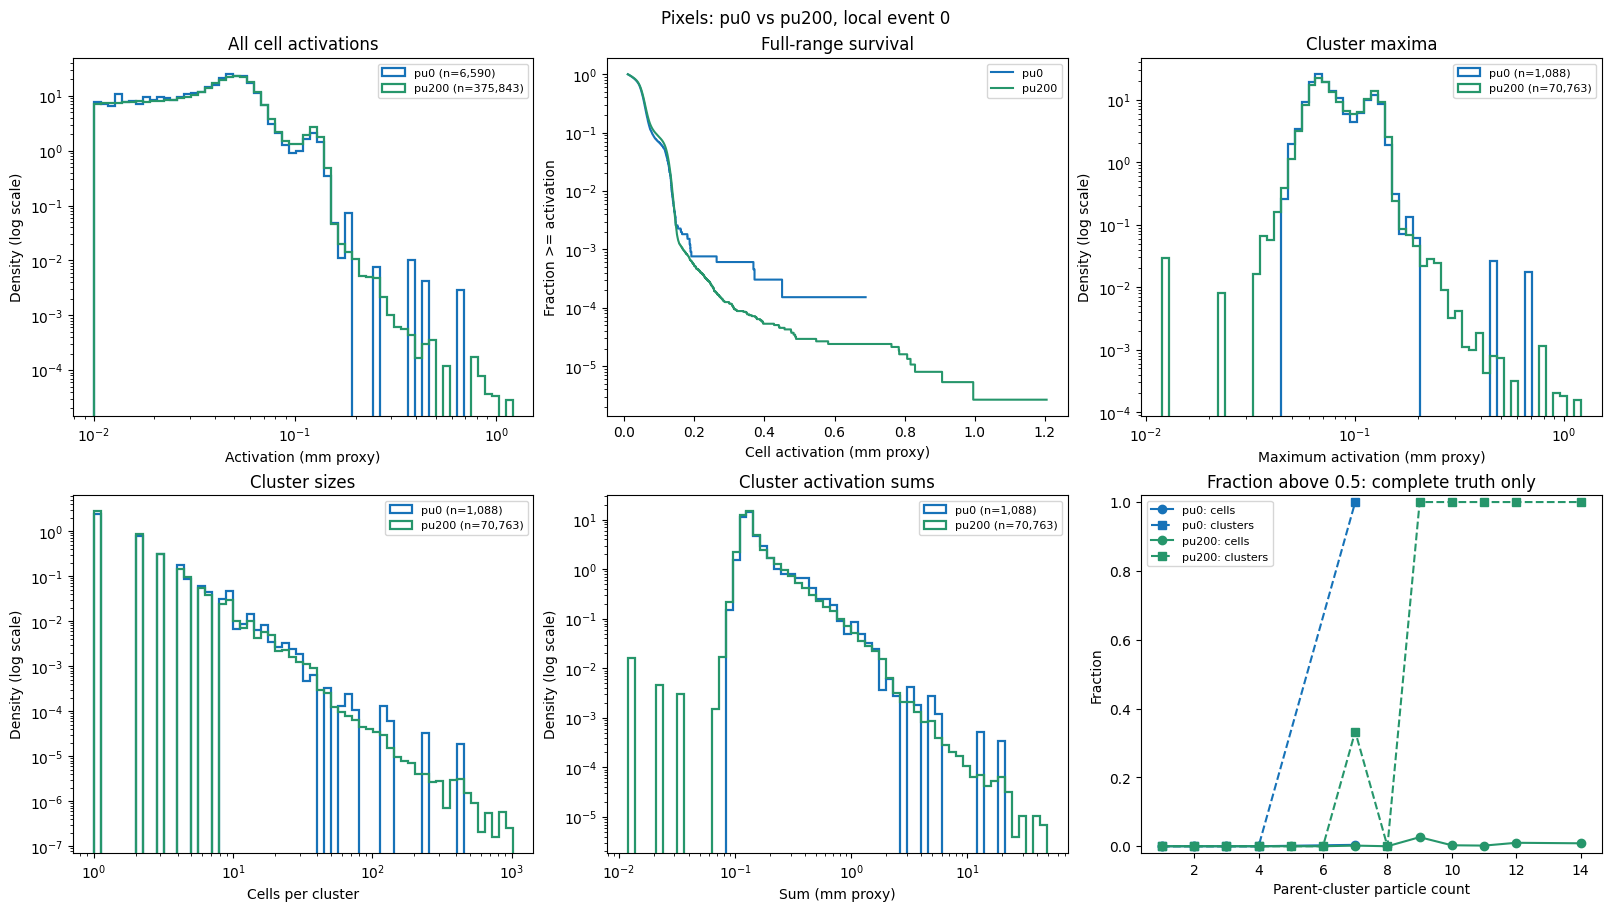

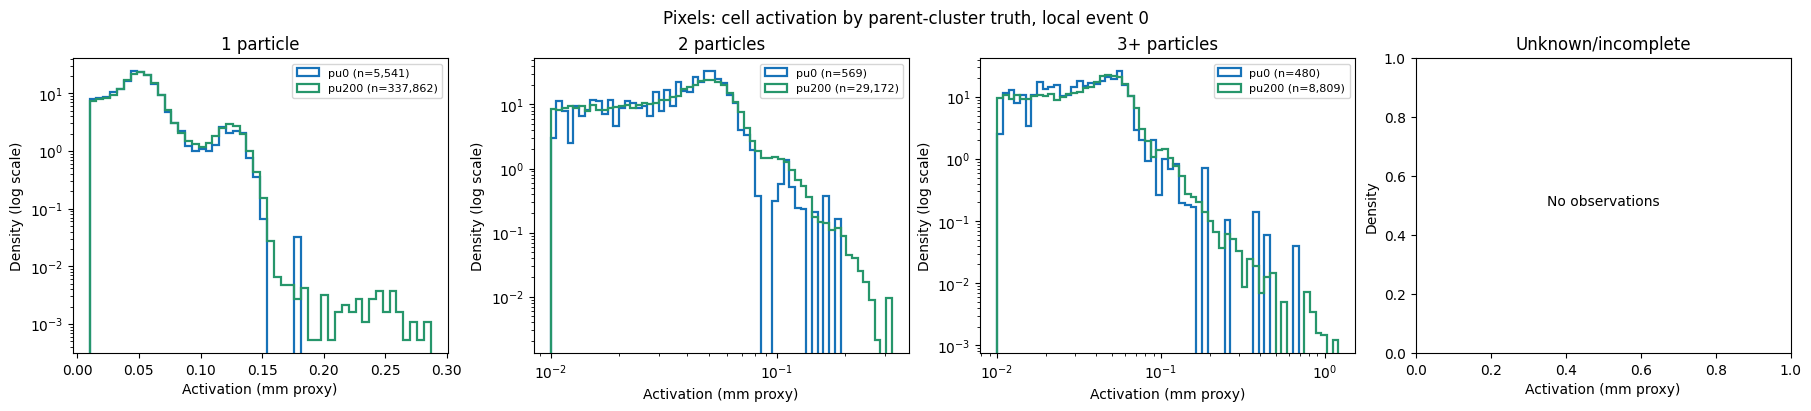

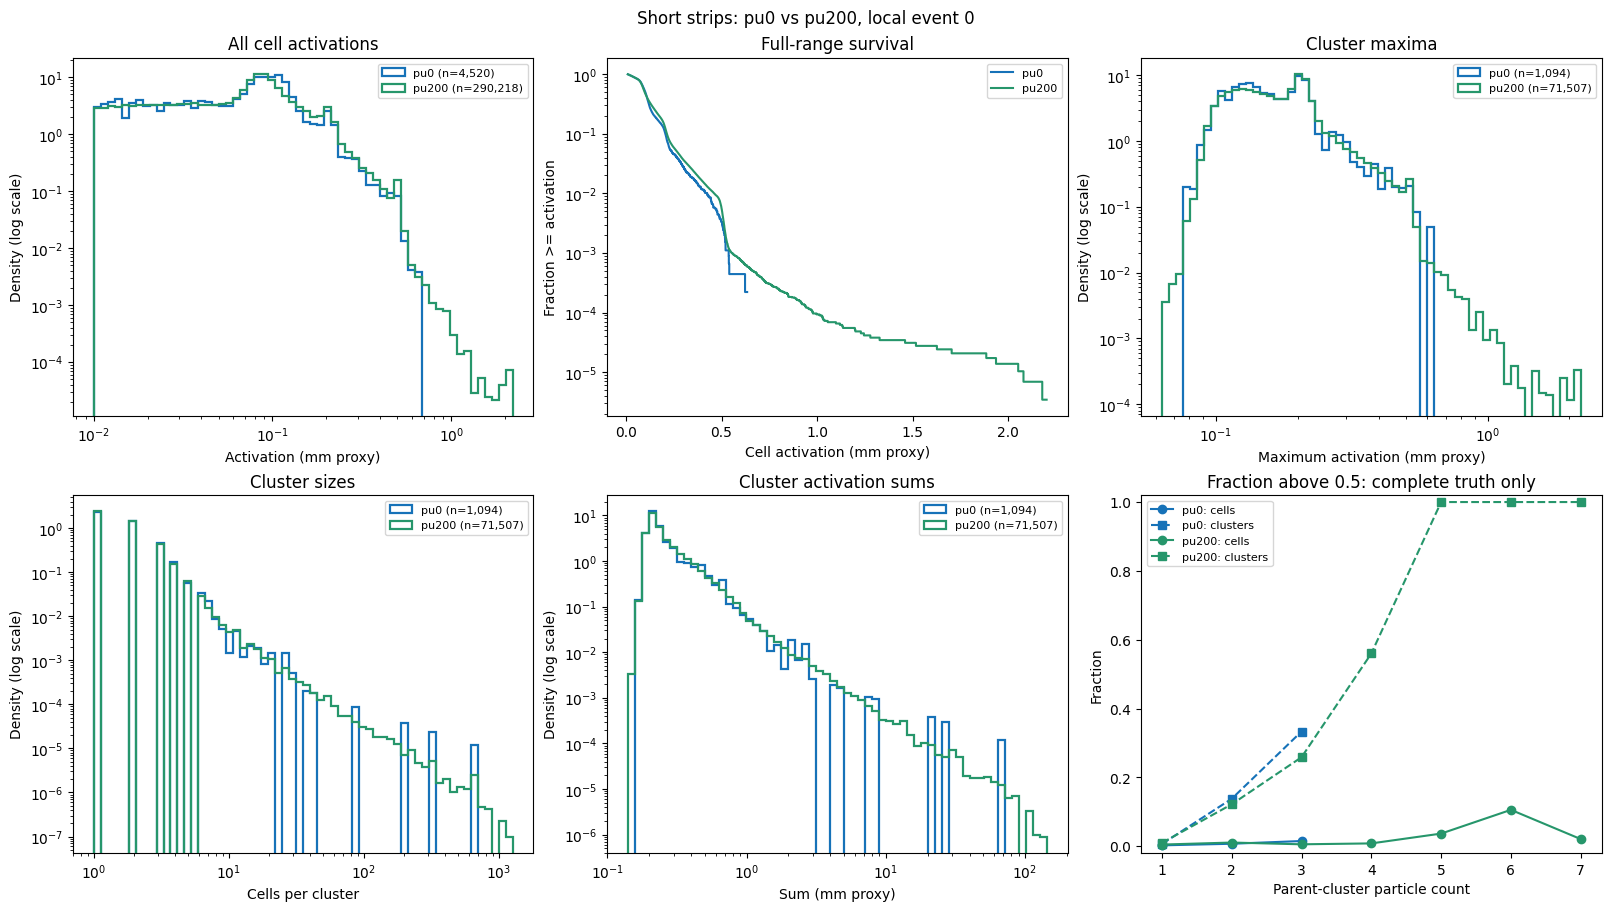

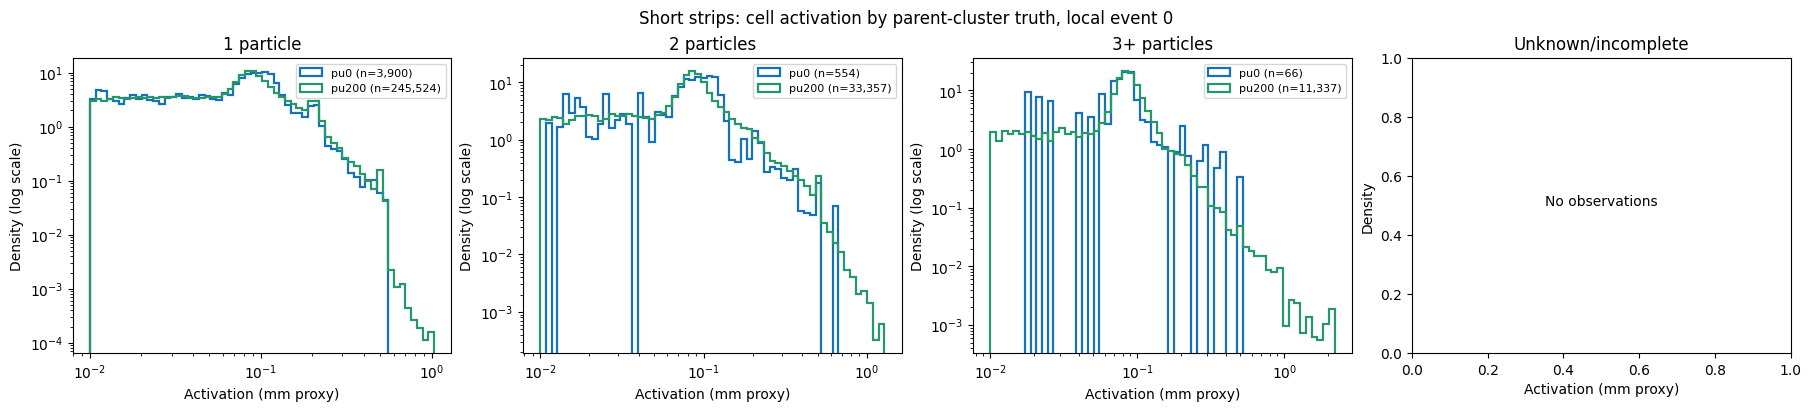

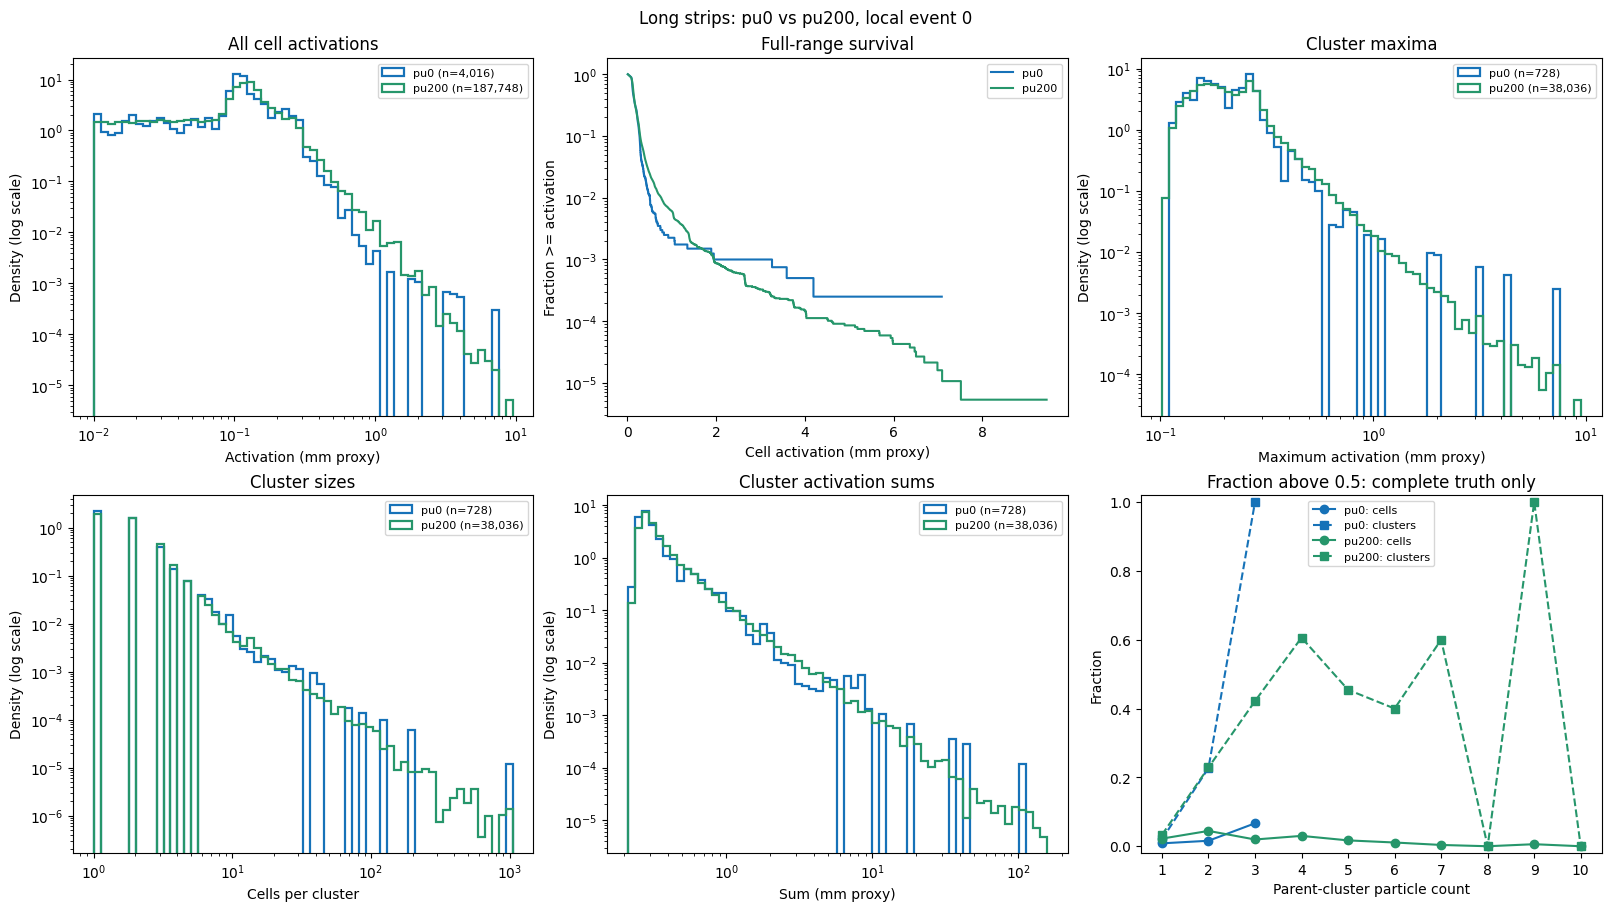

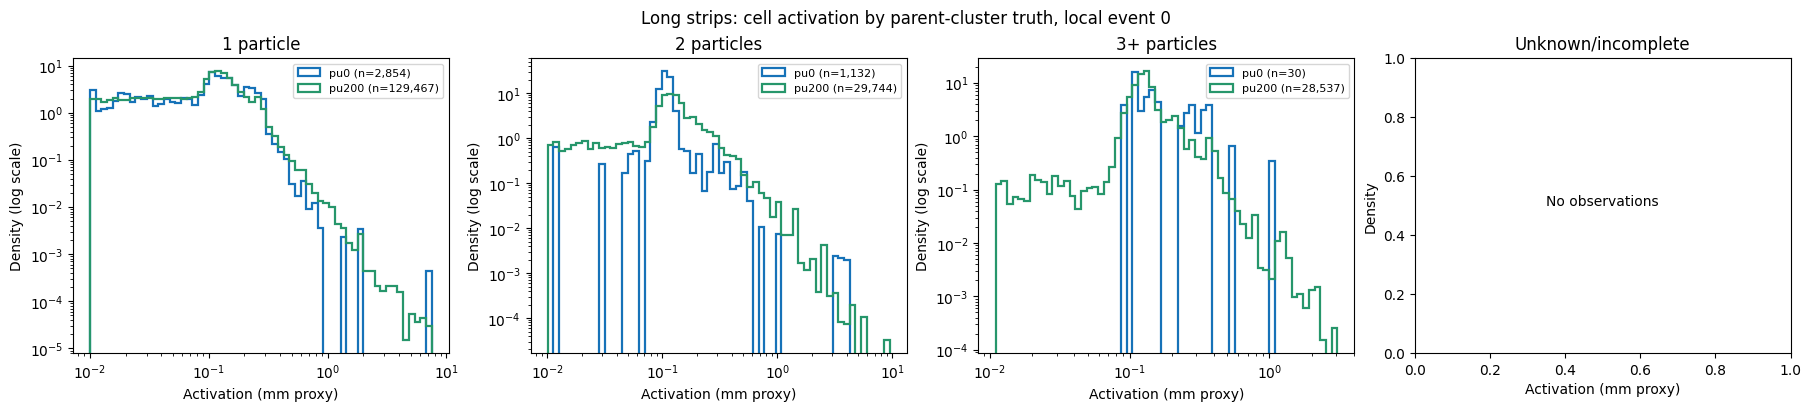

In [7]:
display(paired.pileup_event_summary(analyses))
display(paired.contributor_statistics(analyses))
display(paired.largest_cells(analyses, per_sample=10))
paired.plot_pileup_comparison(analyses)

## Frozen P99.9 pixel-code validation

The mapping was calibrated on ttbar pu200, not refitted to Higgs portal. Recompute every selected pixel code from the stored boundaries with upper-bin ties. Require positive codes 1-15 on pixels and null codes on strips.

Code 15 includes its nominal bin and true overflow. The table distinguishes all code-15 cells from values beyond the nominal code-15 bin end. This validates storage and frozen-map application, not electronics realism or a calibrated ATLAS response.

,scheme,pixel_cells,code15_cells,code15_fraction,genuinely_clipped_cells,clipped_fraction,native_max,checks
sample,,,,,,,,
pu0,p99.9,6590,12,0.001821,12,0.001821,0.688644,PASS
pu200,p99.9,375843,398,0.001059,317,0.000843,1.205180,PASS


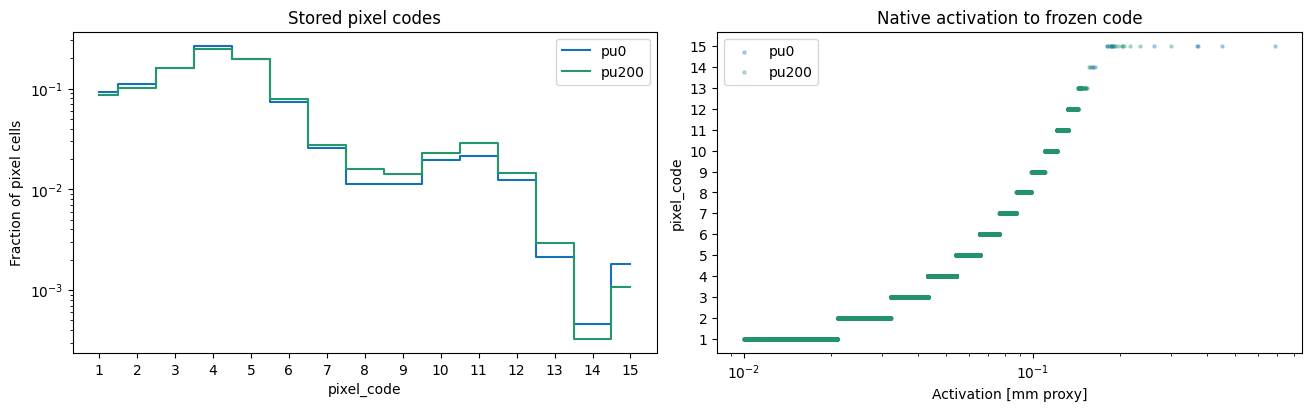

In [8]:
display(validation.quantization(samples))
validation.plot_codes(samples)

## Example cluster images

Six different available cluster sizes per detector type, nearest to the configured targets, selected deterministically. Each gallery has a shared native-activation color scale. Images show actual channel addresses with one channel of padding; square drawn pixels do not imply square physical cells. There is no image-window cropping. Change `GALLERY_SAMPLE` to inspect the other sample.

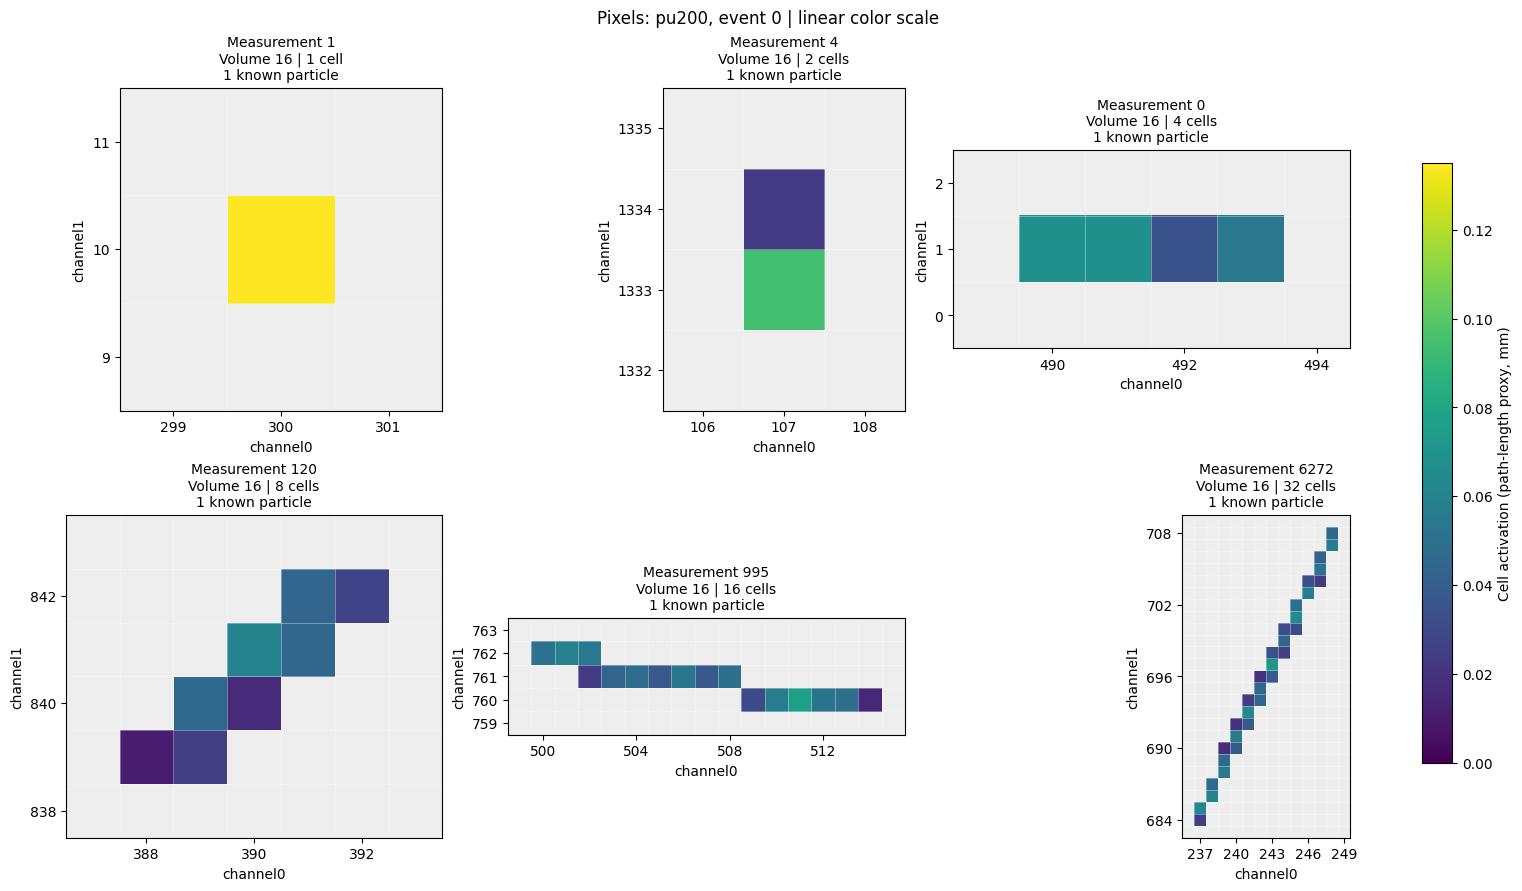

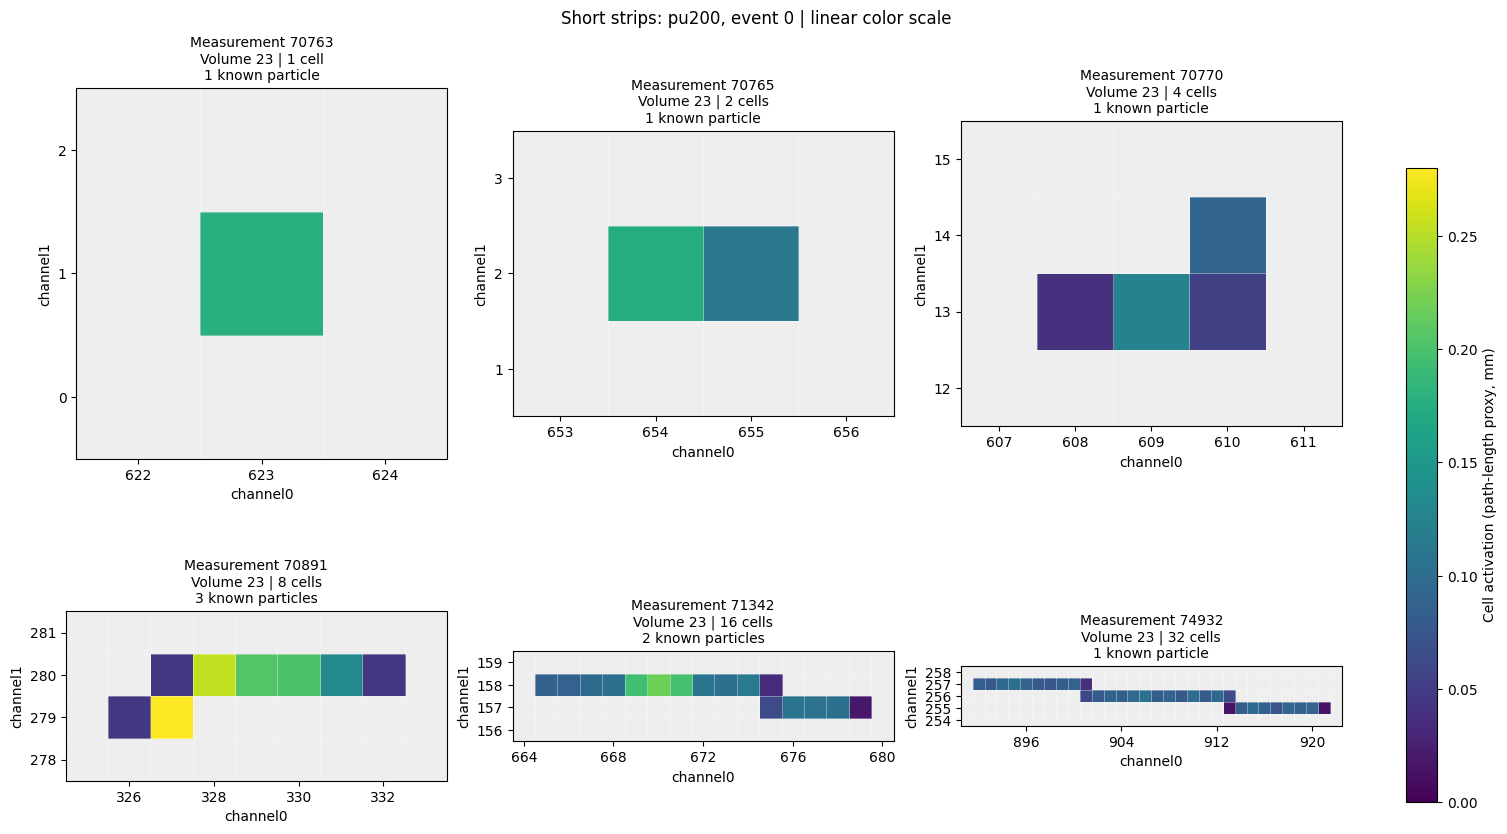

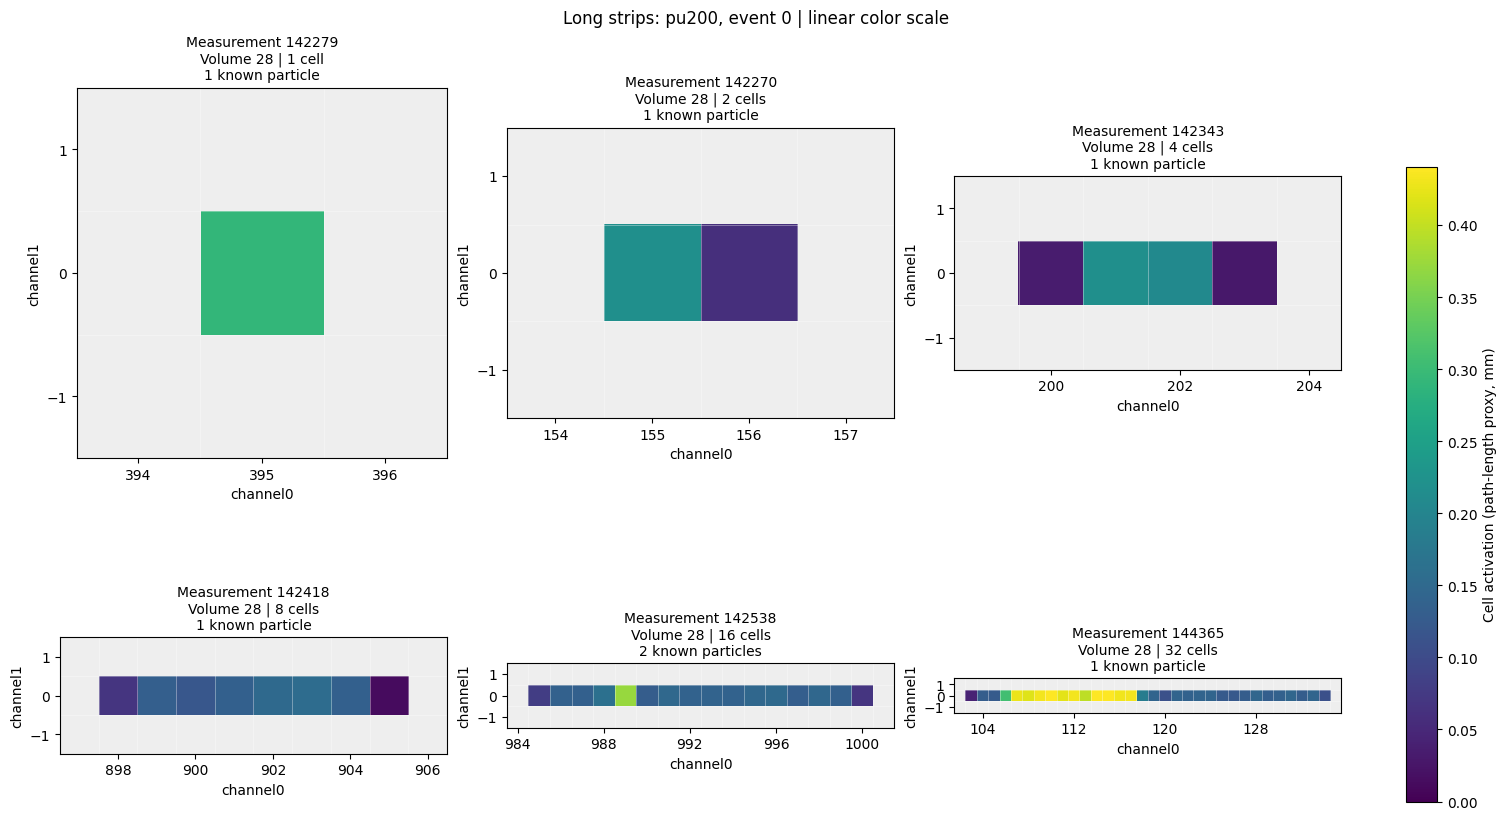

,Detector type,Target cells,Measurement ID,Volume,Cells,Known particles,Truth complete,Value sum,Minimum value,Maximum value
0,Pixels,1,1,16,1,1,True,0.135059,0.135059,0.135059
1,Pixels,2,4,16,2,1,True,0.117096,0.022730,0.094366
2,Pixels,4,0,16,4,1,True,0.224250,0.034261,0.067912
3,Pixels,8,120,16,8,1,True,0.275309,0.010974,0.060268
4,Pixels,16,995,16,16,1,True,0.742671,0.015686,0.076466
5,Pixels,32,6272,16,32,1,True,1.362258,0.017328,0.071534
6,Short strips,1,70763,23,1,1,True,0.178174,0.178174,0.178174
7,Short strips,2,70765,23,2,1,True,0.285459,0.111781,0.173678
8,Short strips,4,70770,23,4,1,True,0.307837,0.039519,0.124941
9,Short strips,8,70891,23,8,3,True,1.208504,0.043850,0.280334


In [9]:
display(validation.cluster_gallery(samples[GALLERY_SAMPLE], CLUSTER_TARGET_SIZES))

## Read-only confirmation and interpretation

The checks above establish file consistency, associations, feature availability, detector coverage and correct frozen encoding. They do **not** establish physical resolution, mass/lifetime reconstruction, downstream tracking efficiency, or event-matched pileup effects. Those require additional reconstruction and larger/matched samples.

Save this notebook after running it to retain figures and tables for review.

In [10]:
if CHECK_SOURCE_HASHES:
    after_hashes = validation.file_hashes(PAIRED_ROOT)
    assert before_hashes == after_hashes, "Source Parquet contents changed during analysis"
    print("PASS: all six source Parquet SHA256 checksums are unchanged")
else:
    print("Source checksum verification was disabled")
print("Validation cells completed; review warnings, missingness and legacy-label disagreements above.")

PASS: all six source Parquet SHA256 checksums are unchanged
Validation cells completed; review warnings, missingness and legacy-label disagreements above.


## Current stored truth-perigee validation

This section tests the **current `PAIRED_ROOT` Parquet files** against the independent reference for the same event. The original reference is hash-checked against `BASELINE_PAIRED_ROOT`; all non-perigee particle features must match that baseline before its reference is reused. Current ROOT writer provenance and its input checksum are also checked.

The reference uses SciPy DOP853 Lorentz integration in the queried ODD field, independently of ACTS's stepper. The chosen branch is the local transverse-distance minimum nearest production in absolute path length, searching both directions within a finite bound. These are numerical truth-parameter checks, not detector resolution measurements.

Under the recovery-only policy, all original finite perigees must remain exactly unchanged. New recoveries must agree with the independent reference. Known legacy reference discrepancies are reported as `legacy_mismatch_preserved`; unresolved values remain NaN. Residuals below use actual values from the current Parquets, not the older diagnostic candidates. ROOT does not store the propagation path length, so no current path residual is claimed.


In [11]:
print("Current Parquet directory being tested:", PAIRED_ROOT)
reference_summary, comparisons, uniform_checks, current_perigee_checks = validation.load_current_perigee_validation(
    samples, BASELINE_PAIRED_ROOT, PERIGEE_VALIDATION_ROOT)
display(current_perigee_checks)
display(pd.Series({key: reference_summary[key] for key in (
    "mode", "branch_convention", "reference", "input_precision", "tolerances_mm",
    "uniform_cases", "uniform_reference_pass", "source_files_unchanged")}).to_frame("Validation settings"))
# These test the independent reference, not the old ACTS candidate outputs.
display(uniform_checks[["case", "bz_T", "charge", "reference_pass",
                        "reference_delta_d0", "reference_delta_z0"]])
display(validation.perigee_validation_statistics(comparisons))
display(comparisons.loc[comparisons.status != "pass", [
    "sample", "particle_id", "pdg_id", "pt_GeV", "originally_finite",
    "method", "reference_status", "status", "candidate_d0", "candidate_z0",
    "delta_d0", "delta_z0"]])


Current Parquet directory being tested: /misc/home/atlas/dittmeier/git/cluster_extraction/exports/higgs-portal-pilot-run1-n1/paired


,sample,particles,legacy_finite_preserved,selected_generator_particles,selected_finite,recovered_validated,unresolved,legacy_reference_mismatches,writer,particle_file
0,pu0,2908,1412,125,124,20,1,0,writer-recovery-v2,/misc/home/atlas/dittmeier/git/cluster_extract...
1,pu200,221842,126359,7257,7256,249,1,2,writer-recovery-v2,/misc/home/atlas/dittmeier/git/cluster_extract...


,Validation settings
mode,current stored recovery-only perigees
branch_convention,Nearest local transverse-distance minimum in a...
reference,SciPy DOP853 Lorentz integration and event-roo...
input_precision,Stored float32 phase space
tolerances_mm,"{'d0': 0.001, 'z0': 0.01, 'reference_d0': 0.00..."
uniform_cases,20
uniform_reference_pass,20
source_files_unchanged,True


,case,bz_T,charge,reference_pass,reference_delta_d0,reference_delta_z0
0,0,2.0,-1.0,True,1.397146e-14,1.421085e-14
1,0,2.0,1.0,True,-3.511427e-14,-9.059420e-14
2,0,4.0,-1.0,True,-1.039099e-14,4.440892e-14
3,0,4.0,1.0,True,2.897682e-14,-4.263256e-14
4,1,2.0,-1.0,True,5.684342e-14,-1.421085e-14
5,1,2.0,1.0,True,-5.684342e-14,2.557954e-13
6,1,4.0,-1.0,True,2.842171e-14,9.237056e-14
7,1,4.0,1.0,True,2.842171e-14,-1.705303e-13
8,2,2.0,-1.0,True,0.000000e+00,4.547474e-13
9,2,2.0,1.0,True,4.263256e-14,-3.637979e-12


,sample,cohort,particles,passed,status_counts,d0_median_um,d0_p95_um,d0_max_um,z0_median_um,z0_p95_um,z0_max_um
0,pu0,Formerly NaN,21,20,"{'pass': 20, 'unresolved': 1}",6.272457e-04,0.002065,0.008505,0.026206,0.103182,0.107771
1,pu0,Stored finite,104,104,{'pass': 104},3.616277e-07,0.001128,0.003142,0.004398,0.061840,0.180351
2,pu200,Formerly NaN,250,249,"{'pass': 249, 'unresolved': 1}",3.876006e-04,0.004357,0.012970,0.004586,0.050311,0.128454
3,pu200,Stored finite,7007,7005,"{'pass': 7005, 'legacy_mismatch_preserved': 2}",2.601137e-07,0.000030,2.114381,0.001265,0.015108,191.537408


,sample,particle_id,pdg_id,pt_GeV,originally_finite,method,reference_status,status,candidate_d0,candidate_z0,delta_d0,delta_z0
91,pu0,713,211,0.103722,False,current stored Parquet,ok,unresolved,NaN,NaN,NaN,NaN
956,pu200,7633,-211,0.066455,True,current stored Parquet,ok,legacy_mismatch_preserved,36.133171,3498.390869,-0.000482,0.144282
2418,pu200,22398,-211,0.050208,True,current stored Parquet,ok,legacy_mismatch_preserved,-21.055788,-4549.294434,0.002114,-0.191537
2437,pu200,22453,211,0.003601,False,current stored Parquet,ok,unresolved,NaN,NaN,NaN,NaN


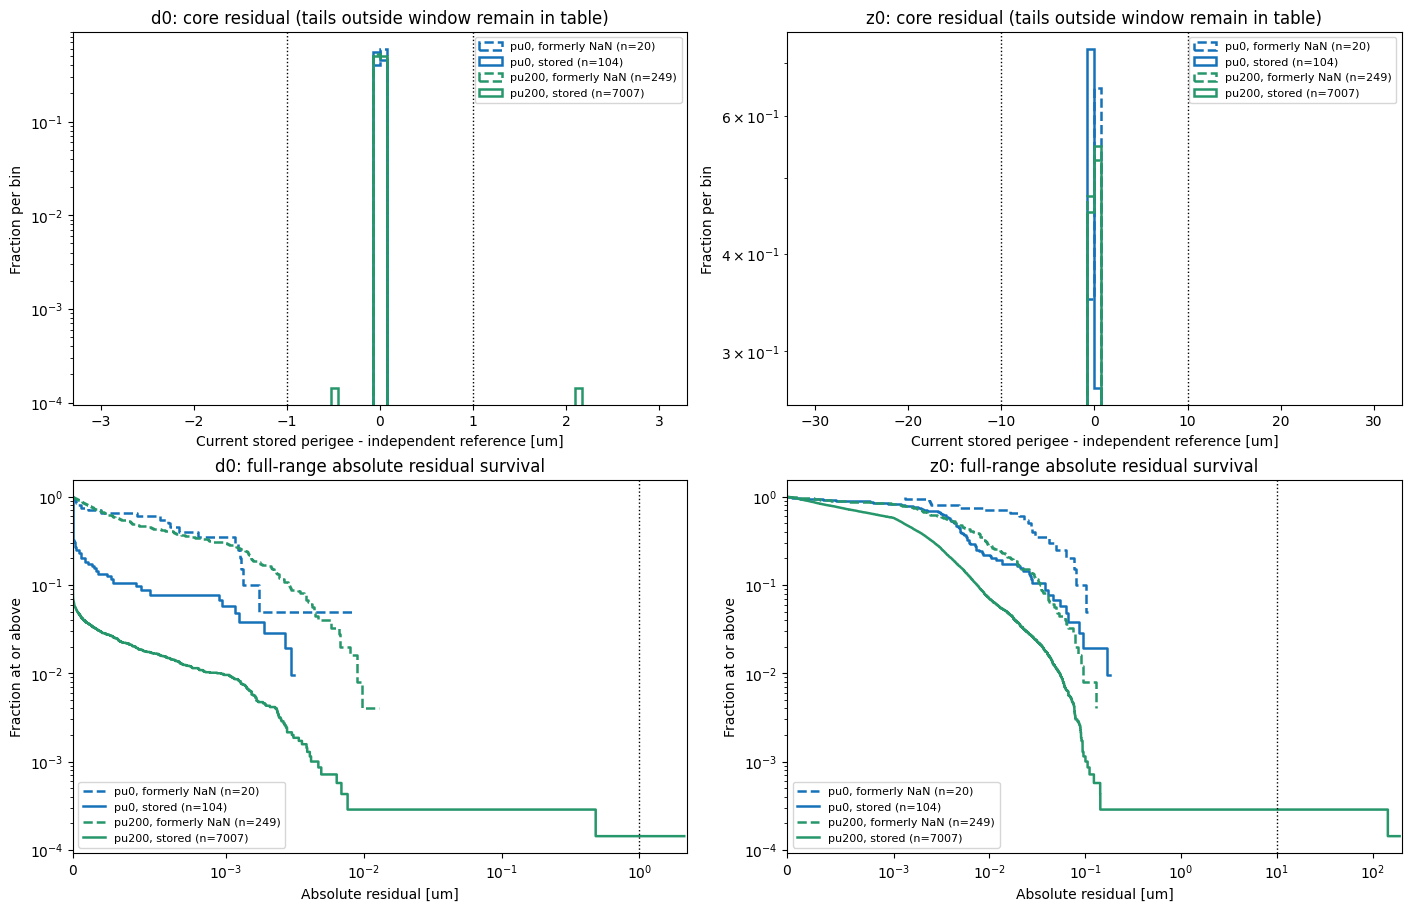

,sample,particle_id,momentum_drift,reference_curvature,reference_status
3183,pu200,29659,3.663736e-15,0.972116,ok
742,pu200,5748,2.664535e-15,0.009336,ok
2928,pu200,27331,6.661338e-16,0.484745,ok
5647,pu200,53655,6.661338e-16,0.278643,ok
605,pu200,4640,4.440892e-16,0.541876,ok
2018,pu200,18613,4.440892e-16,0.083146,ok
2438,pu200,22454,4.440892e-16,0.999559,ok
1371,pu200,11673,3.330669e-16,0.481403,ok
3,pu0,72,2.220446e-16,0.990257,ok
4,pu0,73,2.220446e-16,0.468354,ok


,sample,particle_id,reference_converged,refinement_levels,reference_delta_tighter_d0,reference_delta_tighter_z0
0,pu0,66,True,1.0,8.673617e-19,0.000000e+00
1,pu0,68,True,1.0,0.000000e+00,-1.421085e-14
2,pu0,71,True,1.0,1.561251e-17,0.000000e+00
3,pu0,72,True,1.0,9.676504e-18,0.000000e+00
4,pu0,73,True,1.0,8.673617e-19,0.000000e+00
...,...,...,...,...,...,...
7202,pu200,69317,True,1.0,1.421085e-14,2.966516e-13
7203,pu200,69318,True,1.0,-2.948752e-13,1.136868e-13
7356,pu200,70800,True,1.0,-1.776357e-15,-3.197442e-14
7357,pu200,70801,True,1.0,2.131628e-14,-2.096101e-13


PASS: current Parquets tested; original finite perigees preserved; new recoveries validated; source files unchanged.


In [12]:
validation.plot_perigee_validation(comparisons, reference_summary, value_label="Current stored perigee")
display(comparisons.nlargest(10, "momentum_drift")[
    ["sample", "particle_id", "momentum_drift", "reference_curvature", "reference_status"]])
checked = comparisons[comparisons.reference_converged.notna()]
display(checked[["sample", "particle_id", "reference_converged", "refinement_levels",
                 "reference_delta_tighter_d0", "reference_delta_tighter_z0"]])
assert reference_summary["source_files_unchanged"]
if CHECK_SOURCE_HASHES:
    assert before_hashes == validation.file_hashes(PAIRED_ROOT)
print("PASS: current Parquets tested; original finite perigees preserved; new recoveries validated; source files unchanged.")
